## Imports and load the data

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout, LSTM, GRU
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam


from sklearn.metrics import classification_report, confusion_matrix,accuracy_score, precision_score, recall_score, f1_score


nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("shashwatwork/consume-complaints-dataset-fo-nlp")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'consume-complaints-dataset-fo-nlp' dataset.
Path to dataset files: /kaggle/input/consume-complaints-dataset-fo-nlp


In [3]:
!ls /kaggle/input/consume-complaints-dataset-fo-nlp

complaints_processed.csv


In [4]:
path = kagglehub.dataset_download("shashwatwork/consume-complaints-dataset-fo-nlp")
file_path = os.path.join(path, "complaints_processed.csv")

df = pd.read_csv(file_path)
print("Shape:", df.shape)
df.head()

Using Colab cache for faster access to the 'consume-complaints-dataset-fo-nlp' dataset.
Shape: (162421, 3)


,Unnamed: 0,product,narrative
0,0,credit_card,purchase order day shipping amount receive pro...
1,1,credit_card,forwarded message date tue subject please inve...
2,2,retail_banking,forwarded message cc sent friday pdt subject f...
3,3,credit_reporting,payment history missing credit report speciali...
4,4,credit_reporting,payment history missing credit report made mis...


## EDA

### Clean up and check missing values

In [5]:
df.info()
print("Columns:", df.columns.tolist())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 162421 entries, 0 to 162420
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   Unnamed: 0  162421 non-null  int64 
 1   product     162421 non-null  object
 2   narrative   162411 non-null  object
dtypes: int64(1), object(2)
memory usage: 3.7+ MB
Columns: ['Unnamed: 0', 'product', 'narrative']


In [6]:
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

print(df.isnull().sum())

df = df.dropna(subset=['narrative'])
print("Shape after dropping nulls:", df.shape)

product       0
narrative    10
dtype: int64
Shape after dropping nulls: (162411, 2)


### Class Distribution

product
credit_reporting       91172
debt_collection        23148
mortgages_and_loans    18990
credit_card            15566
retail_banking         13535
Name: count, dtype: int64


/tmp/ipykernel_1390/16007224.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='product', data=df, order=df['product'].value_counts().index, palette='viridis')


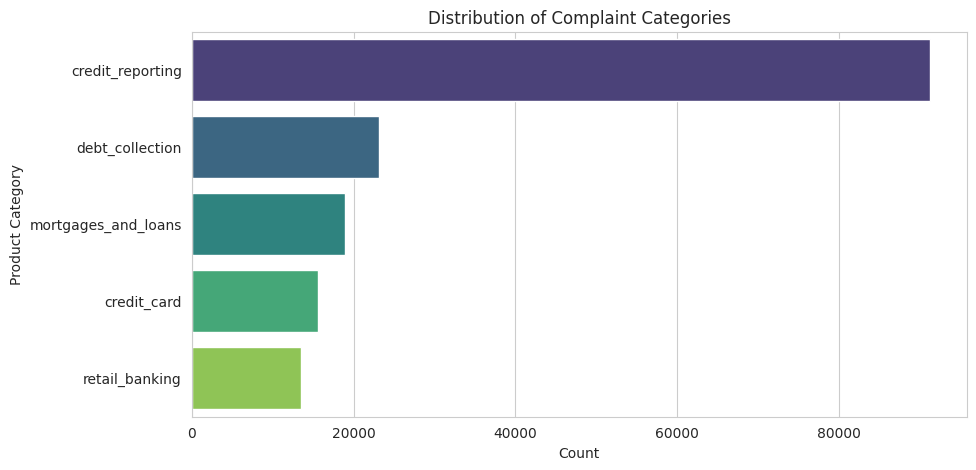

In [7]:
print(df['product'].value_counts())

plt.figure(figsize=(10,5))
sns.countplot(y='product', data=df, order=df['product'].value_counts().index, palette='viridis')
plt.title("Distribution of Complaint Categories")
plt.xlabel("Count")
plt.ylabel("Product Category")
plt.show()

### Text Length Analysis

count    162411.000000
mean         80.232798
std         108.872213
min           1.000000
25%          27.000000
50%          50.000000
75%          95.000000
max        2685.000000
Name: text_length, dtype: float64


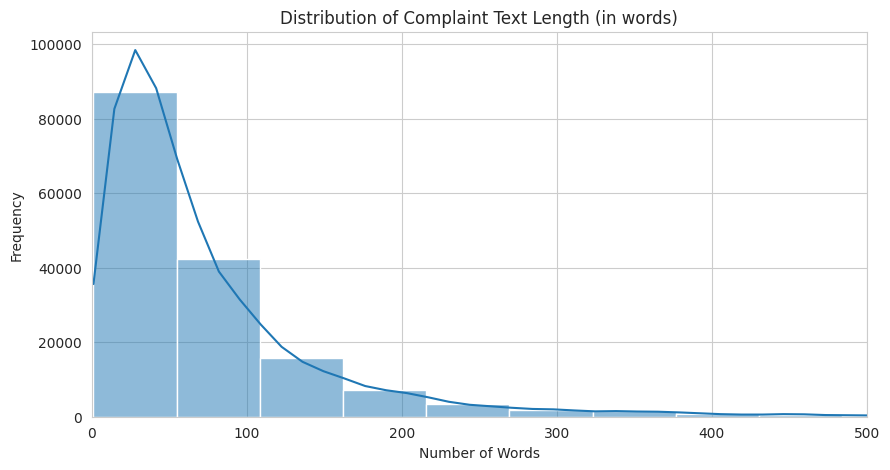

In [8]:
df['text_length'] = df['narrative'].apply(lambda x: len(str(x).split()))
print(df['text_length'].describe())

plt.figure(figsize=(10,5))
sns.histplot(df['text_length'], bins=50, kde=True)
plt.title("Distribution of Complaint Text Length (in words)")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.xlim(0, 500)
plt.show()

In [9]:
# Show Samples

for i in range(3):
    print(f"--- Sample {i+1} (Category: {df['product'].iloc[i]}) ---")
    print(df['narrative'].iloc[i][:300])
    print()

--- Sample 1 (Category: credit_card) ---
purchase order day shipping amount receive product week sent followup email exact verbiage paid two day shipping received order company responded im sorry inform due unusually high order volume order shipped several week stock since early due high demand although continuing take order guaranteeing r

--- Sample 2 (Category: credit_card) ---
forwarded message date tue subject please investigate comenity bank retailer card scam sent hello name scammed comenity bank credit card provider company childrens place new york forever victoria secret original credit comenity bank lower limit began charge overage fee along late fee began pay close

--- Sample 3 (Category: retail_banking) ---
forwarded message cc sent friday pdt subject final legal payment well fargo well fargo clearly wrong need look actually opened account see court hearing several different government agency reporting well including branch put open account numerous fraudulent charge debit

## Text Preprocessing

In [10]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = str(text).lower()                                  # lowercasing
    text = re.sub(r'[^a-z\s]', '', text)                      # remove punctuation & numbers
    text = text.split()
    text = [word for word in text if word not in stop_words]  # remove stop words
    text = [lemmatizer.lemmatize(word) for word in text]      # lemmatization
    return ' '.join(text)

In [11]:
df['clean_narrative'] = df['narrative'].apply(clean_text)
df[['narrative', 'clean_narrative']].head()

,narrative,clean_narrative
0,purchase order day shipping amount receive pro...,purchase order day shipping amount receive pro...
1,forwarded message date tue subject please inve...,forwarded message date tue subject please inve...
2,forwarded message cc sent friday pdt subject f...,forwarded message cc sent friday pdt subject f...
3,payment history missing credit report speciali...,payment history missing credit report speciali...
4,payment history missing credit report made mis...,payment history missing credit report made mis...


count    162411.000000
mean         80.207935
std         108.821314
min           1.000000
25%          27.000000
50%          50.000000
75%          95.000000
max        2684.000000
Name: clean_text_length, dtype: float64


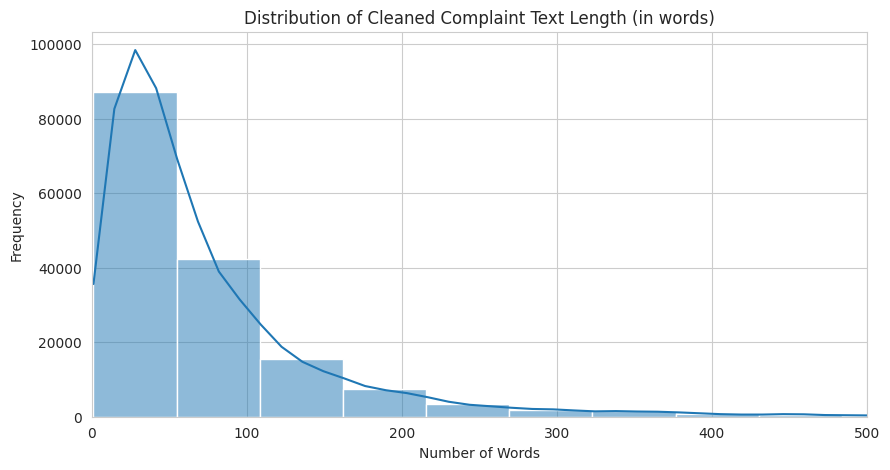

In [12]:
df['clean_text_length'] = df['clean_narrative'].apply(lambda x: len(x.split()))
print(df['clean_text_length'].describe())

plt.figure(figsize=(10,5))
sns.histplot(df['clean_text_length'], bins=50, kde=True)
plt.title("Distribution of Cleaned Complaint Text Length (in words)")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.xlim(0, 500)
plt.show()

## Encoding Labels + Tokenization + Padding

### Encode labels

In [13]:
label_encoder = LabelEncoder()
df['label'] = label_encoder.fit_transform(df['product'])

# show mapping
for i, class_name in enumerate(label_encoder.classes_):
    print(i, '->', class_name)

0 -> credit_card
1 -> credit_reporting
2 -> debt_collection
3 -> mortgages_and_loans
4 -> retail_banking


### Split the data

In [14]:
X_train_text, X_temp_text, y_train, y_temp = train_test_split(
    df['clean_narrative'], df['label'],
    test_size=0.3, random_state=42, stratify=df['label']
)

X_val_text, X_test_text, y_val, y_test = train_test_split(
    X_temp_text, y_temp,
    test_size=0.5, random_state=42, stratify=y_temp
)

print("Train:", X_train_text.shape)
print("Val:", X_val_text.shape)
print("Test:", X_test_text.shape)

Train: (113687,)
Val: (24362,)
Test: (24362,)


### Tokenizer

In [15]:
MAX_VOCAB_SIZE = 20000
MAX_LEN = 150

tokenizer = Tokenizer(num_words=MAX_VOCAB_SIZE, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train_text)

print("Tokenizer fitted on training data.")

vocab_size = len(tokenizer.word_index) + 1
print("Vocabulary size:", vocab_size)

Tokenizer fitted on training data.
Vocabulary size: 39359


### Convert text to sequences + padding

In [16]:
X_train_seq = tokenizer.texts_to_sequences(X_train_text)
X_val_seq = tokenizer.texts_to_sequences(X_val_text)
X_test_seq = tokenizer.texts_to_sequences(X_test_text)

X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding='post', truncating='post')
X_val_pad = pad_sequences(X_val_seq, maxlen=MAX_LEN, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=MAX_LEN, padding='post', truncating='post')

### Handle class imbalance

In [17]:
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weights_dict = dict(enumerate(class_weights))
print(class_weights_dict)

{0: np.float64(2.0867657856093977), 1: np.float64(0.3562738953306174), 2: np.float64(1.4031967415452975), 3: np.float64(1.7104791995787256), 4: np.float64(2.3999788895925693)}


## Evaluate model function

In [18]:
def evaluate_model(model, X_test, y_test_labels, label_encoder, model_name="Model"):
    # predictions
    y_pred_probs = model.predict(X_test)
    y_pred = np.argmax(y_pred_probs, axis=1)

    # metrics
    acc = accuracy_score(y_test_labels, y_pred)
    precision = precision_score(y_test_labels, y_pred, average='weighted')
    recall = recall_score(y_test_labels, y_pred, average='weighted')
    f1 = f1_score(y_test_labels, y_pred, average='weighted')

    print(f"===== {model_name} - Test Set Results =====")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-score:  {f1:.4f}")
    print()

    # classification report (per class)
    print(classification_report(y_test_labels, y_pred, target_names=label_encoder.classes_))

    # confusion matrix
    cm = confusion_matrix(y_test_labels, y_pred)
    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=label_encoder.classes_,
                yticklabels=label_encoder.classes_)
    plt.title(f'{model_name} - Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

    return {
        'model_name': model_name,
        'accuracy': acc,
        'precision': precision,
        'recall': recall,
        'f1_score': f1
    }

## Simple RNN Model

In [19]:
NUM_CLASSES = len(label_encoder.classes_)

y_train_cat = to_categorical(y_train, num_classes=NUM_CLASSES)
y_val_cat = to_categorical(y_val, num_classes=NUM_CLASSES)
y_test_cat = to_categorical(y_test, num_classes=NUM_CLASSES)

In [20]:
EMBEDDING_DIM = 128


model_rnn = Sequential([
    Embedding(input_dim=vocab_size, output_dim=EMBEDDING_DIM, input_length=MAX_LEN),
    SimpleRNN(64, return_sequences=False),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(NUM_CLASSES, activation='softmax')
])

optimizer = Adam(learning_rate=0.0005, clipnorm=1.0)

model_rnn.compile(
    loss='categorical_crossentropy',
    optimizer=optimizer,
    metrics=['accuracy']
)

model_rnn.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [21]:
early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)

history_rnn = model_rnn.fit(
    X_train_pad, y_train_cat,
    validation_data=(X_val_pad, y_val_cat),
    epochs=40,
    batch_size=128,
    class_weight=class_weights_dict,
    callbacks=[early_stop]
)

Epoch 1/40
889/889 ━━━━━━━━━━━━━━━━━━━━ 27s 23ms/step - accuracy: 0.4147 - loss: 1.4726 - val_accuracy: 0.2517 - val_loss: 1.3311
Epoch 2/40
889/889 ━━━━━━━━━━━━━━━━━━━━ 15s 16ms/step - accuracy: 0.4542 - loss: 1.3481 - val_accuracy: 0.5892 - val_loss: 1.1325
Epoch 3/40
889/889 ━━━━━━━━━━━━━━━━━━━━ 15s 16ms/step - accuracy: 0.5434 - loss: 1.1351 - val_accuracy: 0.6635 - val_loss: 1.0302
Epoch 4/40
889/889 ━━━━━━━━━━━━━━━━━━━━ 15s 16ms/step - accuracy: 0.6302 - loss: 0.9982 - val_accuracy: 0.6872 - val_loss: 0.9324
Epoch 5/40
889/889 ━━━━━━━━━━━━━━━━━━━━ 15s 16ms/step - accuracy: 0.6907 - loss: 0.9235 - val_accuracy: 0.5899 - val_loss: 1.0430
Epoch 6/40
889/889 ━━━━━━━━━━━━━━━━━━━━ 15s 16ms/step - accuracy: 0.7038 - loss: 0.8819 - val_accuracy: 0.6099 - val_loss: 1.0577
Epoch 7/40
889/889 ━━━━━━━━━━━━━━━━━━━━ 15s 17ms/step - accuracy: 0.7217 - loss: 0.8497 - val_accuracy: 0.6974 - val_loss: 0.8795
Epoch 8/40
889/889 ━━━━━━━━━━━━━━━━━━━━ 15s 16ms/step - accuracy: 0.7205 - loss: 0.8521 - 

762/762 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step
===== SimpleRNN - Test Set Results =====
Accuracy:  0.7493
Precision: 0.7839
Recall:    0.7493
F1-score:  0.7595

                     precision    recall  f1-score   support

        credit_card       0.53      0.73      0.62      2335
   credit_reporting       0.93      0.78      0.85     13676
    debt_collection       0.65      0.65      0.65      3472
mortgages_and_loans       0.52      0.74      0.61      2849
     retail_banking       0.71      0.71      0.71      2030

           accuracy                           0.75     24362
          macro avg       0.67      0.72      0.69     24362
       weighted avg       0.78      0.75      0.76     24362



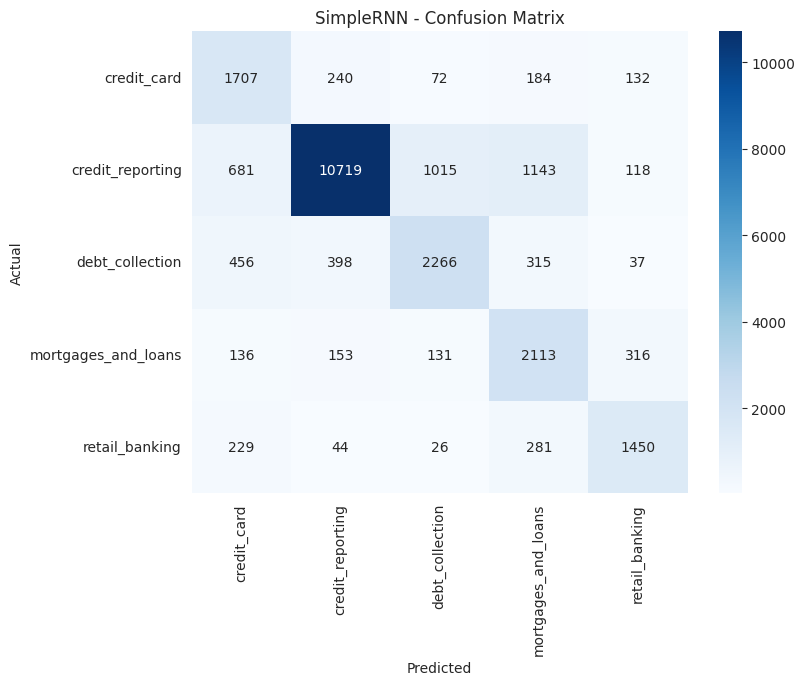

In [22]:
results_rnn = evaluate_model(model_rnn, X_test_pad, y_test, label_encoder, model_name="SimpleRNN")

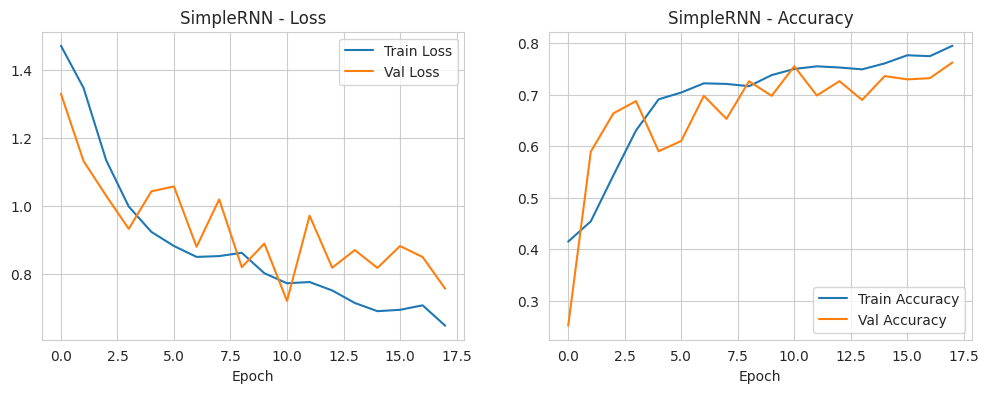

In [23]:
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history_rnn.history['loss'], label='Train Loss')
plt.plot(history_rnn.history['val_loss'], label='Val Loss')
plt.title('SimpleRNN - Loss')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history_rnn.history['accuracy'], label='Train Accuracy')
plt.plot(history_rnn.history['val_accuracy'], label='Val Accuracy')
plt.title('SimpleRNN - Accuracy')
plt.xlabel('Epoch')
plt.legend()

plt.show()

## LSTM Model

In [24]:
EMBEDDING_DIM = 128

model_lstm = Sequential([
    Embedding(input_dim=vocab_size, output_dim=EMBEDDING_DIM, input_length=MAX_LEN),
    LSTM(64, return_sequences=False),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(NUM_CLASSES, activation='softmax')
])

optimizer = Adam(learning_rate=0.0005, clipnorm=1.0)

model_lstm.compile(
    loss='categorical_crossentropy',
    optimizer=optimizer,
    metrics=['accuracy']
)

model_lstm.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [25]:
early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)

history_lstm = model_lstm.fit(
    X_train_pad, y_train_cat,
    validation_data=(X_val_pad, y_val_cat),
    epochs=40,
    batch_size=128,
    class_weight=class_weights_dict,
    callbacks=[early_stop]
)

Epoch 1/40
889/889 ━━━━━━━━━━━━━━━━━━━━ 22s 16ms/step - accuracy: 0.3754 - loss: 1.4614 - val_accuracy: 0.2807 - val_loss: 1.1653
Epoch 2/40
889/889 ━━━━━━━━━━━━━━━━━━━━ 16s 17ms/step - accuracy: 0.5385 - loss: 1.1342 - val_accuracy: 0.7066 - val_loss: 1.0732
Epoch 3/40
889/889 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.7116 - loss: 1.0207 - val_accuracy: 0.7474 - val_loss: 0.9393
Epoch 4/40
889/889 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.7245 - loss: 0.9683 - val_accuracy: 0.7295 - val_loss: 0.9236
Epoch 5/40
889/889 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.7124 - loss: 0.9233 - val_accuracy: 0.7017 - val_loss: 0.8300
Epoch 6/40
889/889 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.7147 - loss: 0.8831 - val_accuracy: 0.7434 - val_loss: 0.7955
Epoch 7/40
889/889 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.7382 - loss: 0.8647 - val_accuracy: 0.7215 - val_loss: 0.9074
Epoch 8/40
889/889 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.7316 - loss: 0.8557 - 

762/762 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step
===== LSTM - Test Set Results =====
Accuracy:  0.8423
Precision: 0.8576
Recall:    0.8423
F1-score:  0.8462

                     precision    recall  f1-score   support

        credit_card       0.69      0.82      0.75      2335
   credit_reporting       0.95      0.84      0.89     13676
    debt_collection       0.70      0.82      0.76      3472
mortgages_and_loans       0.74      0.86      0.80      2849
     retail_banking       0.83      0.89      0.86      2030

           accuracy                           0.84     24362
          macro avg       0.78      0.85      0.81     24362
       weighted avg       0.86      0.84      0.85     24362



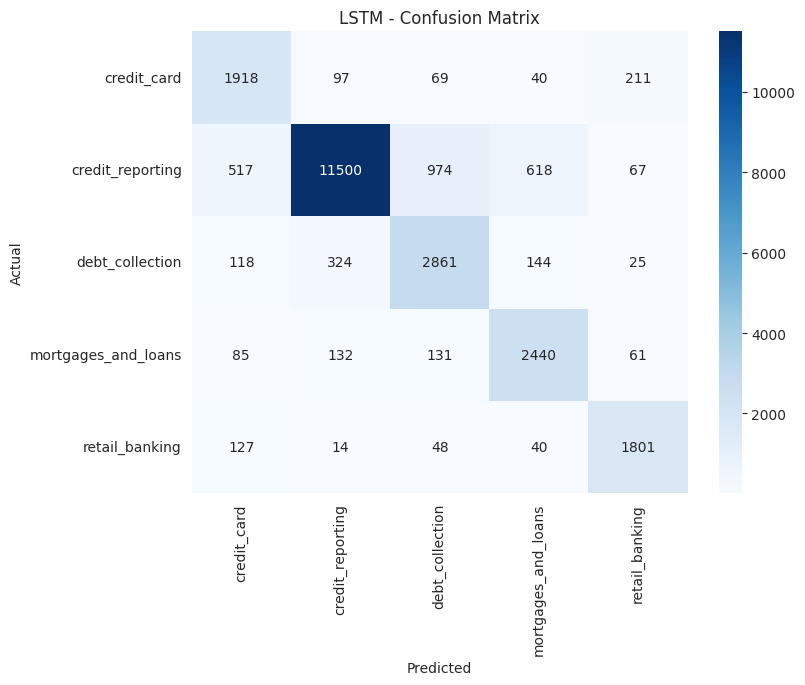

In [26]:
results_lstm = evaluate_model(model_lstm, X_test_pad, y_test, label_encoder, model_name="LSTM")

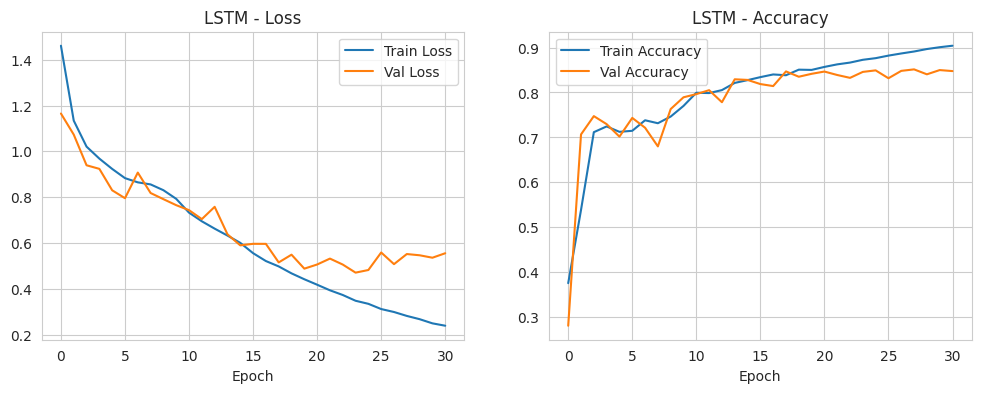

In [27]:
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history_lstm.history['loss'], label='Train Loss')
plt.plot(history_lstm.history['val_loss'], label='Val Loss')
plt.title('LSTM - Loss')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history_lstm.history['accuracy'], label='Train Accuracy')
plt.plot(history_lstm.history['val_accuracy'], label='Val Accuracy')
plt.title('LSTM - Accuracy')
plt.xlabel('Epoch')
plt.legend()

plt.show()

## GRU Model

In [28]:
EMBEDDING_DIM = 128

model_gru = Sequential([
    Embedding(input_dim=vocab_size, output_dim=EMBEDDING_DIM, input_length=MAX_LEN),
    GRU(64, return_sequences=False),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(NUM_CLASSES, activation='softmax')
])

optimizer = Adam(learning_rate=0.0005, clipnorm=1.0)

model_gru.compile(
    loss='categorical_crossentropy',
    optimizer=optimizer,
    metrics=['accuracy']
)

model_gru.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [29]:
early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)

history_gru = model_gru.fit(
    X_train_pad, y_train_cat,
    validation_data=(X_val_pad, y_val_cat),
    epochs=40,
    batch_size=128,
    class_weight=class_weights_dict,
    callbacks=[early_stop]
)

Epoch 1/40
889/889 ━━━━━━━━━━━━━━━━━━━━ 16s 16ms/step - accuracy: 0.3771 - loss: 1.4738 - val_accuracy: 0.6231 - val_loss: 1.3811
Epoch 2/40
889/889 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.4976 - loss: 1.0959 - val_accuracy: 0.7098 - val_loss: 0.8740
Epoch 3/40
889/889 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.7281 - loss: 0.6668 - val_accuracy: 0.8047 - val_loss: 0.5980
Epoch 4/40
889/889 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.8272 - loss: 0.5188 - val_accuracy: 0.8414 - val_loss: 0.5206
Epoch 5/40
889/889 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.8514 - loss: 0.4567 - val_accuracy: 0.8446 - val_loss: 0.5101
Epoch 6/40
889/889 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.8658 - loss: 0.4141 - val_accuracy: 0.8521 - val_loss: 0.4950
Epoch 7/40
889/889 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.8780 - loss: 0.3787 - val_accuracy: 0.8503 - val_loss: 0.4965
Epoch 8/40
889/889 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.8849 - loss: 0.3492 - 

762/762 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step
===== GRU - Test Set Results =====
Accuracy:  0.8500
Precision: 0.8607
Recall:    0.8500
F1-score:  0.8532

                     precision    recall  f1-score   support

        credit_card       0.70      0.80      0.75      2335
   credit_reporting       0.95      0.87      0.90     13676
    debt_collection       0.71      0.84      0.77      3472
mortgages_and_loans       0.79      0.83      0.81      2849
     retail_banking       0.83      0.85      0.84      2030

           accuracy                           0.85     24362
          macro avg       0.79      0.84      0.81     24362
       weighted avg       0.86      0.85      0.85     24362



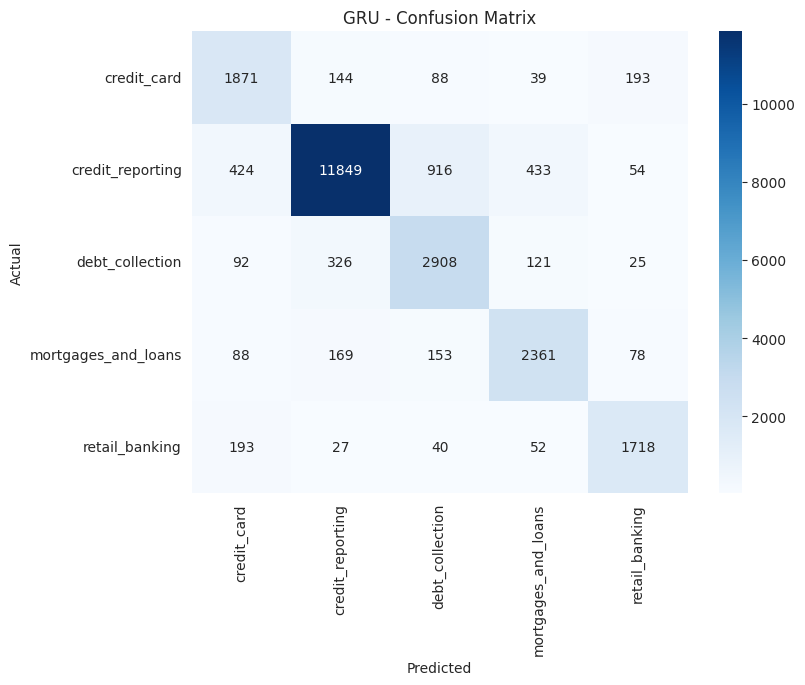

In [30]:
results_gru = evaluate_model(model_gru, X_test_pad, y_test, label_encoder, model_name="GRU")

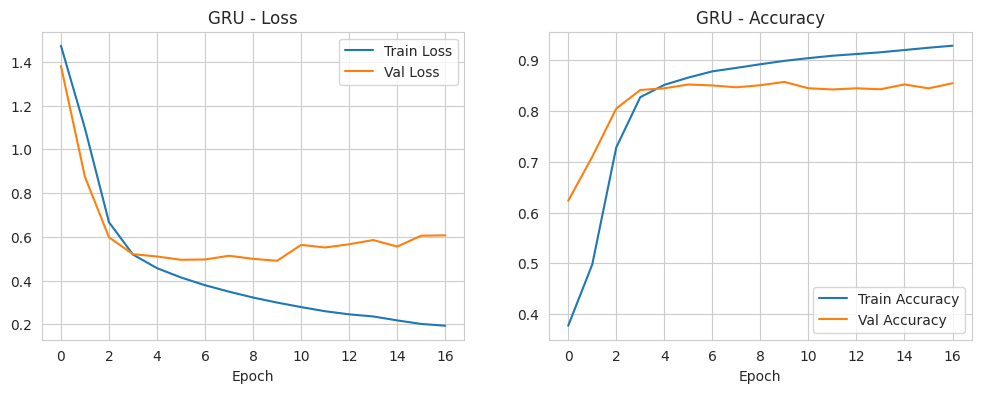

In [31]:
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history_gru.history['loss'], label='Train Loss')
plt.plot(history_gru.history['val_loss'], label='Val Loss')
plt.title('GRU - Loss')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history_gru.history['accuracy'], label='Train Accuracy')
plt.plot(history_gru.history['val_accuracy'], label='Val Accuracy')
plt.title('GRU - Accuracy')
plt.xlabel('Epoch')
plt.legend()

plt.show()

## Fine-tuned Transformer (HuggingFace)

### Setup

Transformers are pretrained on natural, punctuated text, so for this model we feed it the **original** complaint narratives (`narrative`) instead of the heavily preprocessed `clean_narrative` column — removing stopwords/punctuation and lemmatizing throws away information the tokenizer and pretrained weights rely on. We reuse the exact same train/val/test rows as the other models by slicing with the same indices, so the comparison stays fair.

In [32]:
!pip install -q transformers datasets accelerate

In [33]:
import torch
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    EarlyStoppingCallback)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cuda


In [34]:
# Same rows as the other models, but with the raw (uncleaned) narrative text
X_train_text_raw = df.loc[X_train_text.index, 'narrative']
X_val_text_raw = df.loc[X_val_text.index, 'narrative']
X_test_text_raw = df.loc[X_test_text.index, 'narrative']

MODEL_NAME = "distilbert-base-uncased"
MAX_LEN_TR = 150

tf_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

train_hf = Dataset.from_dict({'text': X_train_text_raw.tolist(), 'label': y_train.tolist()})
val_hf = Dataset.from_dict({'text': X_val_text_raw.tolist(), 'label': y_val.tolist()})
test_hf = Dataset.from_dict({'text': X_test_text_raw.tolist(), 'label': y_test.tolist()})

def tokenize_fn(batch):
    return tf_tokenizer(batch['text'], truncation=True, max_length=MAX_LEN_TR)

train_hf = train_hf.map(tokenize_fn, batched=True)
val_hf = val_hf.map(tokenize_fn, batched=True)
test_hf = test_hf.map(tokenize_fn, batched=True)

data_collator = DataCollatorWithPadding(tokenizer=tf_tokenizer)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/113687 [00:00<?, ? examples/s]

Map:   0%|          | 0/24362 [00:00<?, ? examples/s]

Map:   0%|          | 0/24362 [00:00<?, ? examples/s]

### Build the model and handle class imbalance with a weighted loss

In [35]:
transformer_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=NUM_CLASSES
).to(device)

# Reuse the same class weights computed earlier for the RNN/LSTM/GRU models
class_weights_tensor = torch.tensor(
    [class_weights_dict[i] for i in range(NUM_CLASSES)], dtype=torch.float
).to(device)

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fct = torch.nn.CrossEntropyLoss(weight=class_weights_tensor)
        loss = loss_fct(logits, labels)
        return (loss, outputs) if return_outputs else loss

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [36]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {
        'accuracy': accuracy_score(labels, preds),
        'precision': precision_score(labels, preds, average='weighted'),
        'recall': recall_score(labels, preds, average='weighted'),
        'f1': f1_score(labels, preds, average='weighted')
    }

training_args = TrainingArguments(
    output_dir="./transformer_complaint_clf",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    num_train_epochs=5,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    report_to="none"
)

trainer = WeightedTrainer(
    model=transformer_model,
    args=training_args,
    train_dataset=train_hf,
    eval_dataset=val_hf,
    processing_class=tf_tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
)

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.418493,0.415445,0.867129,0.877534,0.867129,0.869959
2,0.350139,0.386138,0.875298,0.884416,0.875298,0.877849
3,0.270810,0.407812,0.882686,0.888886,0.882686,0.884574
4,0.219789,0.462500,0.887283,0.890952,0.887283,0.888536
5,0.172537,0.497174,0.887242,0.890883,0.887242,0.888539


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=17765, training_loss=0.3078908055458745, metrics={'train_runtime': 8765.3824, 'train_samples_per_second': 64.85, 'train_steps_per_second': 2.027, 'total_flos': 2.204965006255878e+16, 'train_loss': 0.3078908055458745, 'epoch': 5.0})

===== Fine-tuned Transformer - Test Set Results =====
Accuracy:  0.8830
Precision: 0.8869
Recall:    0.8830
F1-score:  0.8843

                     precision    recall  f1-score   support

        credit_card       0.77      0.84      0.80      2335
   credit_reporting       0.95      0.91      0.93     13676
    debt_collection       0.78      0.83      0.81      3472
mortgages_and_loans       0.82      0.86      0.84      2849
     retail_banking       0.88      0.89      0.88      2030

           accuracy                           0.88     24362
          macro avg       0.84      0.87      0.85     24362
       weighted avg       0.89      0.88      0.88     24362



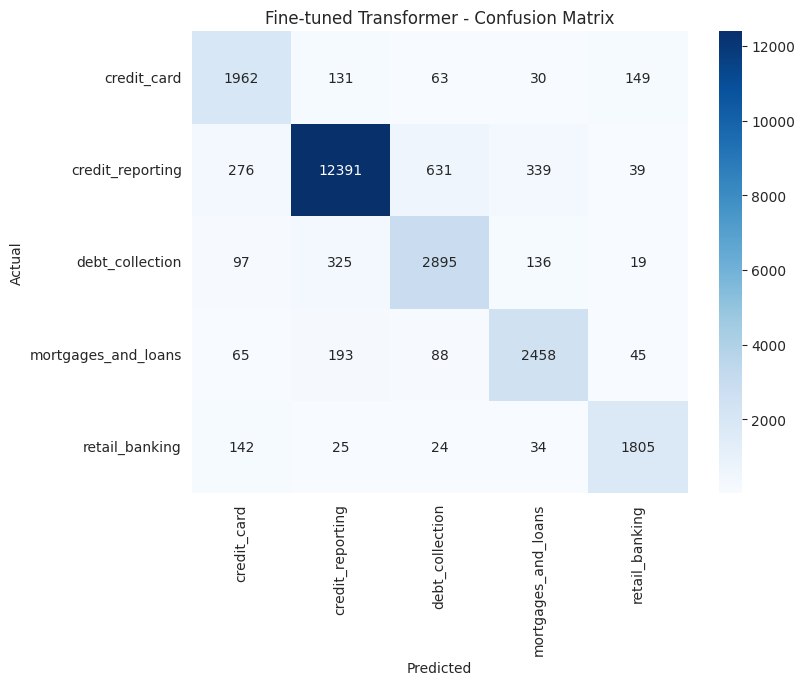

In [37]:
def evaluate_transformer(trainer, test_dataset, y_test_labels, label_encoder, model_name="Fine-tuned Transformer"):
    preds_output = trainer.predict(test_dataset)
    y_pred = np.argmax(preds_output.predictions, axis=1)

    acc = accuracy_score(y_test_labels, y_pred)
    precision = precision_score(y_test_labels, y_pred, average='weighted')
    recall = recall_score(y_test_labels, y_pred, average='weighted')
    f1 = f1_score(y_test_labels, y_pred, average='weighted')

    print(f"===== {model_name} - Test Set Results =====")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-score:  {f1:.4f}")
    print()

    print(classification_report(y_test_labels, y_pred, target_names=label_encoder.classes_))

    cm = confusion_matrix(y_test_labels, y_pred)
    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=label_encoder.classes_,
                yticklabels=label_encoder.classes_)
    plt.title(f'{model_name} - Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

    return {
        'model_name': model_name,
        'accuracy': acc,
        'precision': precision,
        'recall': recall,
        'f1_score': f1
    }

results_transformer = evaluate_transformer(trainer, test_hf, y_test, label_encoder)

## Compare the Four Models

In [38]:
comparison_df = pd.DataFrame([results_rnn, results_lstm, results_gru, results_transformer])
comparison_df = comparison_df.set_index('model_name')[['accuracy', 'precision', 'recall', 'f1_score']]
comparison_df

,accuracy,precision,recall,f1_score
model_name,,,,
SimpleRNN,0.749323,0.783865,0.749323,0.759488
LSTM,0.842295,0.857597,0.842295,0.846211
GRU,0.849971,0.860742,0.849971,0.853195
Fine-tuned Transformer,0.882973,0.886894,0.882973,0.884339


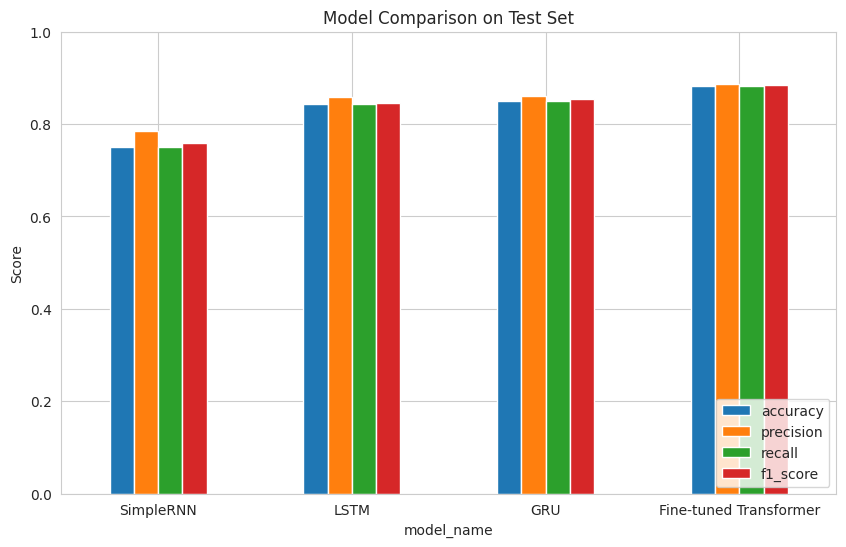

Best performing model (by weighted F1-score): Fine-tuned Transformer


In [39]:
comparison_df.plot(kind='bar', figsize=(10,6))
plt.title('Model Comparison on Test Set')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.show()

best_model_name = comparison_df['f1_score'].idxmax()
print("Best performing model (by weighted F1-score):", best_model_name)

## Classify New Complaints with the Best Model

In [40]:
sample_complaints = [
    "I have been charged twice for the same transaction and the bank refuses to refund me.",
    "My mortgage application was denied without any clear explanation from the loan officer.",
    "Debt collectors keep calling me at work even after I asked them to stop."
]

def predict_complaint(text, model_name):
    if model_name == 'Fine-tuned Transformer':
        inputs = tf_tokenizer(text, truncation=True, max_length=MAX_LEN_TR, return_tensors='pt').to(device)
        transformer_model.eval()
        with torch.no_grad():
            logits = transformer_model(**inputs).logits
        pred_id = torch.argmax(logits, dim=1).item()
    else:
        model_map = {'SimpleRNN': model_rnn, 'LSTM': model_lstm, 'GRU': model_gru}
        model = model_map[model_name]
        cleaned = clean_text(text)
        seq = tokenizer.texts_to_sequences([cleaned])
        pad = pad_sequences(seq, maxlen=MAX_LEN, padding='post', truncating='post')
        pred_probs = model.predict(pad)
        pred_id = np.argmax(pred_probs, axis=1)[0]
    return label_encoder.classes_[pred_id]

for text in sample_complaints:
    category = predict_complaint(text, best_model_name)
    print(f"Complaint: {text}")
    print(f"Predicted category ({best_model_name}): {category}")
    print()

Complaint: I have been charged twice for the same transaction and the bank refuses to refund me.
Predicted category (Fine-tuned Transformer): retail_banking

Complaint: My mortgage application was denied without any clear explanation from the loan officer.
Predicted category (Fine-tuned Transformer): mortgages_and_loans

Complaint: Debt collectors keep calling me at work even after I asked them to stop.
Predicted category (Fine-tuned Transformer): debt_collection

